In [1]:
import pandas as pd
import numpy as np

# Cargar archivo CSV
df = pd.read_csv(
    "Precipitaciones - Huila.csv",
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

# Dimensiones de la base
print("Dimensiones:", df.shape)

# Primeros registros
display(df.head())

# Nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

# Tipos de datos
print("\nInformación general:")
df.info()

Dimensiones: (264, 8)


,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
0,21025030,ALTAMIRA EL GRIFO - AUT [21025030],PRECIPITACION,Precipitación total mensual,2024-01-01 00:00,mm,9.2,Definitivo
1,21025030,ALTAMIRA EL GRIFO - AUT [21025030],PRECIPITACION,Precipitación total mensual,2024-02-01 00:00,mm,122.8,Preliminar
2,21025030,ALTAMIRA EL GRIFO - AUT [21025030],PRECIPITACION,Precipitación total mensual,2024-03-01 00:00,mm,143.0,Preliminar
3,21025030,ALTAMIRA EL GRIFO - AUT [21025030],PRECIPITACION,Precipitación total mensual,2024-04-01 00:00,mm,171.0,Preliminar
4,21025030,ALTAMIRA EL GRIFO - AUT [21025030],PRECIPITACION,Precipitación total mensual,2024-05-01 00:00,mm,227.0,Preliminar



Columnas:
['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad', 'Valor', 'NivelAprobacion']

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 264 entries, 0 to 263
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CodigoEstacion   264 non-null    int64  
 1   NombreEstacion   264 non-null    str    
 2   Variable         264 non-null    str    
 3   Parametro        264 non-null    str    
 4   Fecha            264 non-null    str    
 5   Unidad           264 non-null    str    
 6   Valor            264 non-null    float64
 7   NivelAprobacion  264 non-null    str    
dtypes: float64(1), int64(1), str(6)
memory usage: 40.7 KB


In [2]:
import os
os.getcwd()


'C:\\Users\\juanc'

In [3]:
# Valores faltantes por columna
print("Valores faltantes:")
display(df.isnull().sum())

# Registros duplicados
print("Registros duplicados:", df.duplicated().sum())

# Estadísticas descriptivas
display(df.describe(include="all").T)

Valores faltantes:


CodigoEstacion     0
NombreEstacion     0
Variable           0
Parametro          0
Fecha              0
Unidad             0
Valor              0
NivelAprobacion    0
dtype: int64

Registros duplicados: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CodigoEstacion,264.0,NaN,NaN,NaN,21090617.083333,49150.021791,21015020.0,21025030.0,21085030.0,21145040.0,21145080.0
NombreEstacion,264,8,ALTAMIRA EL GRIFO - AUT [21025030],34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Variable,264,1,PRECIPITACION,264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Parametro,264,1,Precipitación total mensual,264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fecha,264,34,2024-01-01 00:00,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unidad,264,1,mm,264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Valor,264.0,NaN,NaN,NaN,128.698485,106.672757,0.3,54.475,108.65,165.125,557.9
NivelAprobacion,264,2,Preliminar,263,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df.columns.tolist())

['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad', 'Valor', 'NivelAprobacion']


In [5]:
display(df["NombreEstacion"].value_counts())

NombreEstacion
ALTAMIRA EL GRIFO - AUT [21025030]    34
PALACIO-VEGALARGA [21115100]          34
SAN ALFONSO [21145040]                34
SANTA ANA - AUT [21145080]            34
ZULUAGA AUT [21065040]                34
SAN RAFAEL [21085030]                 33
SEVILLA  AUT [21015020]               33
JULIA LA [21135050]                   28
Name: count, dtype: int64

In [6]:
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")

print("Fecha inicial:", df["Fecha"].min())
print("Fecha final:", df["Fecha"].max())
print("Fechas inválidas:", df["Fecha"].isna().sum())

Fecha inicial: 2024-01-01 00:00:00
Fecha final: 2026-10-01 00:00:00
Fechas inválidas: 0


In [7]:
df_temp = pd.read_csv(
    "Temperatura Huila.csv",
    encoding="utf-8-sig"
)

display(df_temp.head())

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
0,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-01-01 00:00,degC,29.508333,Preliminar
1,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-02-01 00:00,degC,28.150575,Preliminar
2,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-03-01 00:00,degC,27.505747,Preliminar
3,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-04-01 00:00,degC,27.146111,Preliminar
4,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-05-01 00:00,degC,26.630108,Preliminar


In [8]:
# Distribución de valores según nivel de aprobación

display(
    df.groupby("NivelAprobacion")["Valor"]
    .agg(["count", "min", "max", "mean", "median", "std"])
)

,count,min,max,mean,median,std
NivelAprobacion,,,,,,
Definitivo,1,9.2,9.2,9.200000,9.2,NaN
Preliminar,263,0.3,557.9,129.152852,109.0,106.619877


In [9]:
# Revisar cuántos registros tienen exactamente 1 mm
display(
    df[df["Valor"] == 1]
    [["NombreEstacion", "Fecha", "Valor", "NivelAprobacion"]]
)

,NombreEstacion,Fecha,Valor,NivelAprobacion


In [10]:
estaciones_precip = set(df["CodigoEstacion"].unique())
estaciones_temp = set(df_temp["CodigoEstacion"].unique())

print("Estaciones con precipitación:", len(estaciones_precip))
print("Estaciones con temperatura:", len(estaciones_temp))
print("Estaciones compartidas:", len(estaciones_precip & estaciones_temp))

print("\nEstaciones que no coinciden:")
print("Solo precipitación:", estaciones_precip - estaciones_temp)
print("Solo temperatura:", estaciones_temp - estaciones_precip)

Estaciones con precipitación: 8
Estaciones con temperatura: 8
Estaciones compartidas: 8

Estaciones que no coinciden:
Solo precipitación: set()
Solo temperatura: set()


In [11]:
for nombre, datos in [
    ("Precipitación", df),
    ("Temperatura", df_temp)
]:
    datos["Fecha"] = pd.to_datetime(datos["Fecha"], errors="coerce")

    print(f"\n{nombre}")
    print("Desde:", datos["Fecha"].min())
    print("Hasta:", datos["Fecha"].max())
    print("Registros:", len(datos))


Precipitación
Desde: 2024-01-01 00:00:00
Hasta: 2026-10-01 00:00:00
Registros: 264

Temperatura
Desde: 2024-01-01 00:00:00
Hasta: 2026-10-01 00:00:00
Registros: 260


In [12]:
# Crear una columna que identifique el mes
df["Mes"] = df["Fecha"].dt.to_period("M")
df_temp["Mes"] = df_temp["Fecha"].dt.to_period("M")

# Contar registros por estación
cobertura_precip = (
    df.groupby("NombreEstacion")
    .size()
    .reset_index(name="Registros_Precipitacion")
)

cobertura_temp = (
    df_temp.groupby("NombreEstacion")
    .size()
    .reset_index(name="Registros_Temperatura")
)

# Comparar ambas bases
cobertura = cobertura_precip.merge(
    cobertura_temp,
    on="NombreEstacion",
    how="outer"
)

display(cobertura)

,NombreEstacion,Registros_Precipitacion,Registros_Temperatura
0,ALTAMIRA EL GRIFO - AUT [21025030],34,34
1,JULIA LA [21135050],28,30
2,PALACIO-VEGALARGA [21115100],34,29
3,SAN ALFONSO [21145040],34,34
4,SAN RAFAEL [21085030],33,32
5,SANTA ANA - AUT [21145080],34,34
6,SEVILLA AUT [21015020],33,33
7,ZULUAGA AUT [21065040],34,34


In [13]:
# Meses esperados entre enero de 2024 y octubre de 2026
meses_esperados = pd.period_range(
    start="2024-01",
    end="2026-10",
    freq="M"
)

def revisar_meses(df, nombre):
    print(f"\n--- {nombre} ---")

    for estacion in df["NombreEstacion"].unique():
        meses_disponibles = set(
            df.loc[df["NombreEstacion"] == estacion, "Mes"]
        )

        faltantes = sorted(set(meses_esperados) - meses_disponibles)

        print(estacion, "| Meses faltantes:", faltantes)

revisar_meses(df, "Precipitación")
revisar_meses(df_temp, "Temperatura")


--- Precipitación ---
ALTAMIRA EL GRIFO - AUT [21025030] | Meses faltantes: []
JULIA LA [21135050] | Meses faltantes: [Period('2024-04', 'M'), Period('2025-07', 'M'), Period('2025-08', 'M'), Period('2025-10', 'M'), Period('2026-09', 'M'), Period('2026-10', 'M')]
PALACIO-VEGALARGA [21115100] | Meses faltantes: []
SAN ALFONSO [21145040] | Meses faltantes: []
SAN RAFAEL [21085030] | Meses faltantes: [Period('2026-10', 'M')]
SANTA ANA - AUT [21145080] | Meses faltantes: []
SEVILLA  AUT [21015020] | Meses faltantes: [Period('2026-10', 'M')]
ZULUAGA AUT [21065040] | Meses faltantes: []

--- Temperatura ---
ALTAMIRA EL GRIFO - AUT [21025030] | Meses faltantes: []
JULIA LA [21135050] | Meses faltantes: [Period('2024-04', 'M'), Period('2025-08', 'M'), Period('2025-10', 'M'), Period('2026-10', 'M')]
PALACIO-VEGALARGA [21115100] | Meses faltantes: [Period('2024-01', 'M'), Period('2024-02', 'M'), Period('2024-03', 'M'), Period('2024-04', 'M'), Period('2024-05', 'M')]
SAN ALFONSO [21145040] | Mese

In [14]:
# Comprobar registros por estación y mes

print("PRECIPITACIÓN")
display(
    df.groupby("NombreEstacion")["Mes"]
    .nunique()
)

print("\nTEMPERATURA")
display(
    df_temp.groupby("NombreEstacion")["Mes"]
    .nunique()
)

PRECIPITACIÓN


NombreEstacion
ALTAMIRA EL GRIFO - AUT [21025030]    34
JULIA LA [21135050]                   28
PALACIO-VEGALARGA [21115100]          34
SAN ALFONSO [21145040]                34
SAN RAFAEL [21085030]                 33
SANTA ANA - AUT [21145080]            34
SEVILLA  AUT [21015020]               33
ZULUAGA AUT [21065040]                34
Name: Mes, dtype: int64


TEMPERATURA


NombreEstacion
ALTAMIRA EL GRIFO - AUT [21025030]    34
JULIA LA [21135050]                   30
PALACIO-VEGALARGA [21115100]          29
SAN ALFONSO [21145040]                34
SAN RAFAEL [21085030]                 32
SANTA ANA - AUT [21145080]            34
SEVILLA  AUT [21015020]               33
ZULUAGA AUT [21065040]                34
Name: Mes, dtype: int64

In [15]:
print("Duplicados estación-mes en precipitación:")
print(
    df.duplicated(
        subset=["CodigoEstacion", "Mes"]
    ).sum()
)

print("Duplicados estación-mes en temperatura:")
print(
    df_temp.duplicated(
        subset=["CodigoEstacion", "Mes"]
    ).sum()
)

Duplicados estación-mes en precipitación:
0
Duplicados estación-mes en temperatura:
0


In [16]:
# Consolidar precipitación y temperatura
df_clima = pd.merge(
    df,
    df_temp,
    on=["CodigoEstacion", "Mes"],
    how="outer",
    suffixes=("_precip", "_temp"),
    indicator=True
)

print("Dimensiones de la base consolidada:", df_clima.shape)

print("\nCoincidencia de registros:")
display(df_clima["_merge"].value_counts())

Dimensiones de la base consolidada: (266, 17)

Coincidencia de registros:


_merge
both          258
left_only       6
right_only      2
Name: count, dtype: int64

In [17]:
# Identificar registros sin coincidencia

registros_sin_coincidencia = df_clima[
    df_clima["_merge"] != "both"
]

display(
    registros_sin_coincidencia[
        [
            "CodigoEstacion",
            "NombreEstacion_precip",
            "NombreEstacion_temp",
            "Mes",
            "_merge"
        ]
    ]
)

,CodigoEstacion,NombreEstacion_precip,NombreEstacion_temp,Mes,_merge
106,21085030,SAN RAFAEL [21085030],NaN,2024-06,left_only
134,21115100,PALACIO-VEGALARGA [21115100],NaN,2024-01,left_only
135,21115100,PALACIO-VEGALARGA [21115100],NaN,2024-02,left_only
136,21115100,PALACIO-VEGALARGA [21115100],NaN,2024-03,left_only
137,21115100,PALACIO-VEGALARGA [21115100],NaN,2024-04,left_only
138,21115100,PALACIO-VEGALARGA [21115100],NaN,2024-05,left_only
185,21135050,NaN,JULIA LA [21135050],2025-07,right_only
197,21135050,NaN,JULIA LA [21135050],2026-09,right_only


In [18]:
print("Parámetros de temperatura:")
display(df_temp["Parametro"].value_counts())

print("\nUnidades de temperatura:")
display(df_temp["Unidad"].value_counts())

Parámetros de temperatura:


Parametro
Temperatura máxima media mensual    260
Name: count, dtype: int64


Unidades de temperatura:


Unidad
degC    260
Name: count, dtype: int64

In [19]:
df_temp = df_temp.rename(columns={
    "Valor": "Temperatura_Maxima_Media",
    "Unidad": "Unidad_Temperatura"
})

df = df.rename(columns={
    "Valor": "Precipitacion_Mensual",
    "Unidad": "Unidad_Precipitacion"
})

In [21]:
print("Columnas disponibles:")
print(datos.columns.tolist())

print("\nPrimeros registros:")
display(datos.head())

Columnas disponibles:
['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad_Temperatura', 'Temperatura_Maxima_Media', 'NivelAprobacion', 'Mes']

Primeros registros:


,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad_Temperatura,Temperatura_Maxima_Media,NivelAprobacion,Mes
0,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-01-01,degC,29.508333,Preliminar,2024-01
1,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-02-01,degC,28.150575,Preliminar,2024-02
2,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-03-01,degC,27.505747,Preliminar,2024-03
3,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-04-01,degC,27.146111,Preliminar,2024-04
4,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-05-01,degC,26.630108,Preliminar,2024-05


In [23]:
import pandas as pd

# Crear copias para el análisis
df_precip_analisis = df.copy()
df_temp_analisis = df_temp.copy()

# Estandarizar nombres de columnas
df_precip_analisis = df_precip_analisis.rename(columns={
    "Valor": "Precipitacion_Mensual",
    "Unidad": "Unidad_Precipitacion"
})

df_temp_analisis = df_temp_analisis.rename(columns={
    "Valor": "Temperatura_Maxima_Media",
    "Temperatura": "Temperatura_Maxima_Media",
    "Unidad": "Unidad_Temperatura"
})

# Configurar fechas y valores numéricos
for datos, variable in [
    (df_precip_analisis, "Precipitacion_Mensual"),
    (df_temp_analisis, "Temperatura_Maxima_Media")
]:
    datos["Fecha"] = pd.to_datetime(
        datos["Fecha"], errors="coerce"
    )

    datos[variable] = pd.to_numeric(
        datos[variable], errors="coerce"
    )

print("Columnas de precipitación:")
print(df_precip_analisis.columns.tolist())

print("\nColumnas de temperatura:")
print(df_temp_analisis.columns.tolist())

print("\nPreparación completada correctamente.")

Columnas de precipitación:
['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad_Precipitacion', 'Precipitacion_Mensual', 'NivelAprobacion', 'Mes']

Columnas de temperatura:
['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad_Temperatura', 'Temperatura_Maxima_Media', 'NivelAprobacion', 'Mes']

Preparación completada correctamente.


In [26]:
# Recuperar el nombre original de temperatura
df_temp_analisis = df_temp_analisis.rename(
    columns={
        "Temperatura_Maxima_Media": "Temperatura"
    }
)

# Verificar el cambio
print("Columnas de temperatura:")
print(df_temp_analisis.columns.tolist())

print("\nPrimeros registros:")
display(df_temp_analisis.head())

Columnas de temperatura:
['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad_Temperatura', 'Temperatura', 'NivelAprobacion', 'Mes']

Primeros registros:


,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad_Temperatura,Temperatura,NivelAprobacion,Mes
0,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-01-01,degC,29.508333,Preliminar,2024-01
1,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-02-01,degC,28.150575,Preliminar,2024-02
2,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-03-01,degC,27.505747,Preliminar,2024-03
3,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-04-01,degC,27.146111,Preliminar,2024-04
4,21025030,ALTAMIRA EL GRIFO - AUT [21025030],TEMPERATURA,Temperatura máxima media mensual,2024-05-01,degC,26.630108,Preliminar,2024-05


In [27]:
estadisticas_precip = (
    df_precip_analisis
    .groupby("NombreEstacion")["Precipitacion_Mensual"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

display(estadisticas_precip)

,count,mean,median,min,max,std
NombreEstacion,,,,,,
ALTAMIRA EL GRIFO - AUT [21025030],34,113.38,103.30,9.2,296.2,64.90
JULIA LA [21135050],28,177.14,150.15,4.8,537.2,145.02
PALACIO-VEGALARGA [21115100],34,128.98,95.20,8.2,509.6,111.92
SAN ALFONSO [21145040],34,81.08,58.35,1.2,242.9,73.79
SAN RAFAEL [21085030],33,199.22,153.00,6.3,557.9,162.64
SANTA ANA - AUT [21145080],34,98.06,75.00,0.3,269.2,65.63
SEVILLA AUT [21015020],33,111.82,109.50,15.4,210.7,46.48
ZULUAGA AUT [21065040],34,130.03,110.70,10.2,480.3,91.91


In [28]:
estadisticas_temp = (
    df_temp_analisis
    .groupby("NombreEstacion")["Temperatura"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

display(estadisticas_temp)

,count,mean,median,min,max,std
NombreEstacion,,,,,,
ALTAMIRA EL GRIFO - AUT [21025030],34,26.41,26.24,24.30,29.51,1.22
JULIA LA [21135050],30,24.57,24.38,22.52,27.25,1.10
PALACIO-VEGALARGA [21115100],29,27.91,27.28,26.33,31.18,1.40
SAN ALFONSO [21145040],34,35.71,35.66,33.11,38.56,1.58
SAN RAFAEL [21085030],32,29.17,28.71,26.61,33.31,1.63
SANTA ANA - AUT [21145080],34,26.36,26.18,24.48,28.98,1.12
SEVILLA AUT [21015020],33,26.69,26.78,24.01,29.22,1.13
ZULUAGA AUT [21065040],34,26.99,26.84,25.13,29.49,1.16


In [29]:
# Revisar nombres actuales
print(df_temp_analisis.columns.tolist())

['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad_Temperatura', 'Temperatura', 'NivelAprobacion', 'Mes']


In [30]:
df_temp_analisis = df_temp_analisis.rename(columns={
    "Temperatura": "Temperatura_Maxima_Media"
})

In [31]:
estadisticas_temp = (
    df_temp_analisis
    .groupby("NombreEstacion")["Temperatura_Maxima_Media"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

display(estadisticas_temp)

,count,mean,median,min,max,std
NombreEstacion,,,,,,
ALTAMIRA EL GRIFO - AUT [21025030],34,26.41,26.24,24.30,29.51,1.22
JULIA LA [21135050],30,24.57,24.38,22.52,27.25,1.10
PALACIO-VEGALARGA [21115100],29,27.91,27.28,26.33,31.18,1.40
SAN ALFONSO [21145040],34,35.71,35.66,33.11,38.56,1.58
SAN RAFAEL [21085030],32,29.17,28.71,26.61,33.31,1.63
SANTA ANA - AUT [21145080],34,26.36,26.18,24.48,28.98,1.12
SEVILLA AUT [21015020],33,26.69,26.78,24.01,29.22,1.13
ZULUAGA AUT [21065040],34,26.99,26.84,25.13,29.49,1.16


In [32]:
display(
    df_temp_analisis[
        df_temp_analisis["NombreEstacion"].str.contains(
            "SAN ALFONSO", case=False, na=False
        )
    ][["Fecha", "Temperatura_Maxima_Media", "Unidad_Temperatura"]]
    .sort_values("Fecha")
)

,Fecha,Temperatura_Maxima_Media,Unidad_Temperatura
93,2024-01-01,37.328611,degC
94,2024-02-01,36.844643,degC
95,2024-03-01,38.141667,degC
96,2024-04-01,35.940000,degC
97,2024-05-01,35.554839,degC
98,2024-06-01,35.550278,degC
99,2024-07-01,36.065323,degC
100,2024-08-01,37.123889,degC
101,2024-09-01,38.564722,degC
102,2024-10-01,37.097024,degC


In [33]:
print("Valores nulos en precipitación:")
display(df_precip_analisis.isnull().sum())

print("Registros de Julia La:")
display(
    df_precip_analisis[
        df_precip_analisis["NombreEstacion"].str.contains(
            "JULIA LA", case=False, na=False
        )
    ][["Fecha", "Precipitacion_Mensual", "NivelAprobacion"]]
    .sort_values("Fecha")
)

Valores nulos en precipitación:


CodigoEstacion           0
NombreEstacion           0
Variable                 0
Parametro                0
Fecha                    0
Unidad_Precipitacion     0
Precipitacion_Mensual    0
NivelAprobacion          0
Mes                      0
dtype: int64

Registros de Julia La:


,Fecha,Precipitacion_Mensual,NivelAprobacion
34,2024-01-01,59.6,Preliminar
35,2024-02-01,132.4,Preliminar
36,2024-03-01,161.0,Preliminar
37,2024-05-01,269.4,Preliminar
38,2024-06-01,166.2,Preliminar
39,2024-07-01,54.6,Preliminar
40,2024-08-01,13.4,Preliminar
41,2024-09-01,55.5,Preliminar
42,2024-10-01,206.6,Preliminar
43,2024-11-01,537.2,Preliminar


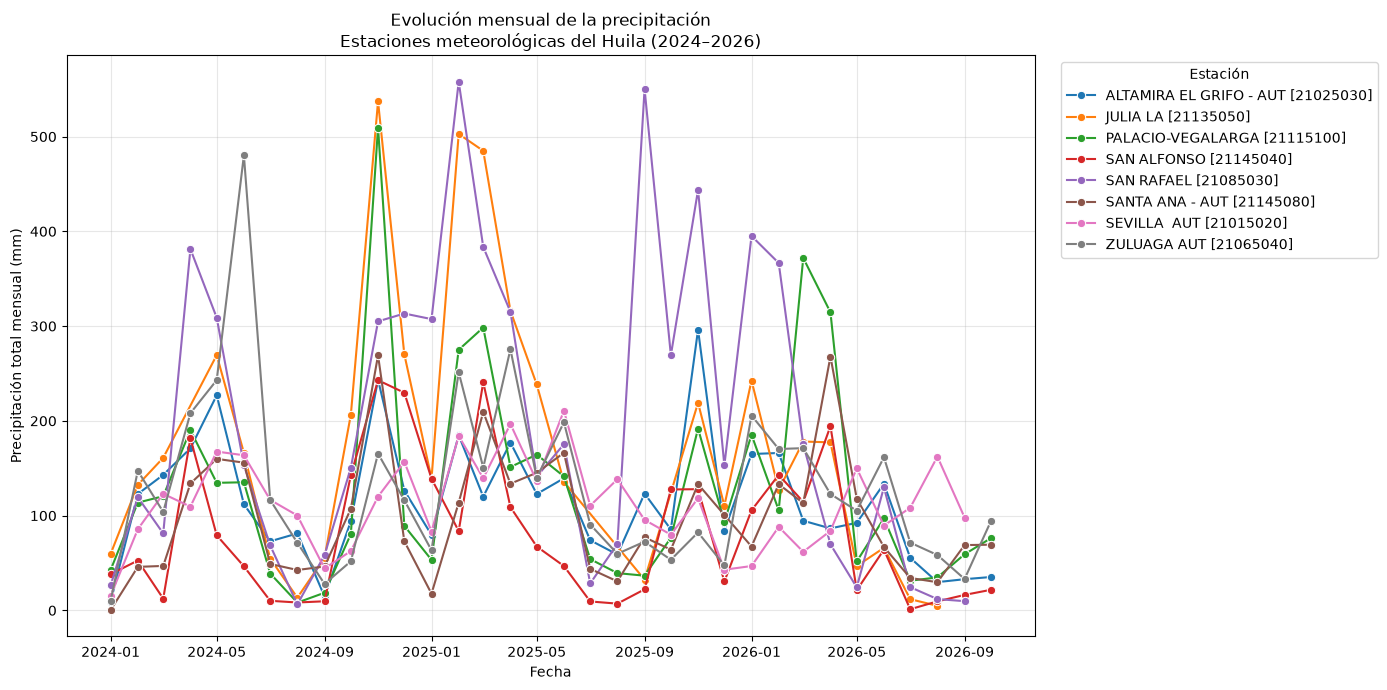

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_precip_analisis,
    x="Fecha",
    y="Precipitacion_Mensual",
    hue="NombreEstacion",
    marker="o"
)

plt.title(
    "Evolución mensual de la precipitación\n"
    "Estaciones meteorológicas del Huila (2024–2026)"
)

plt.xlabel("Fecha")
plt.ylabel("Precipitación total mensual (mm)")
plt.legend(
    title="Estación",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

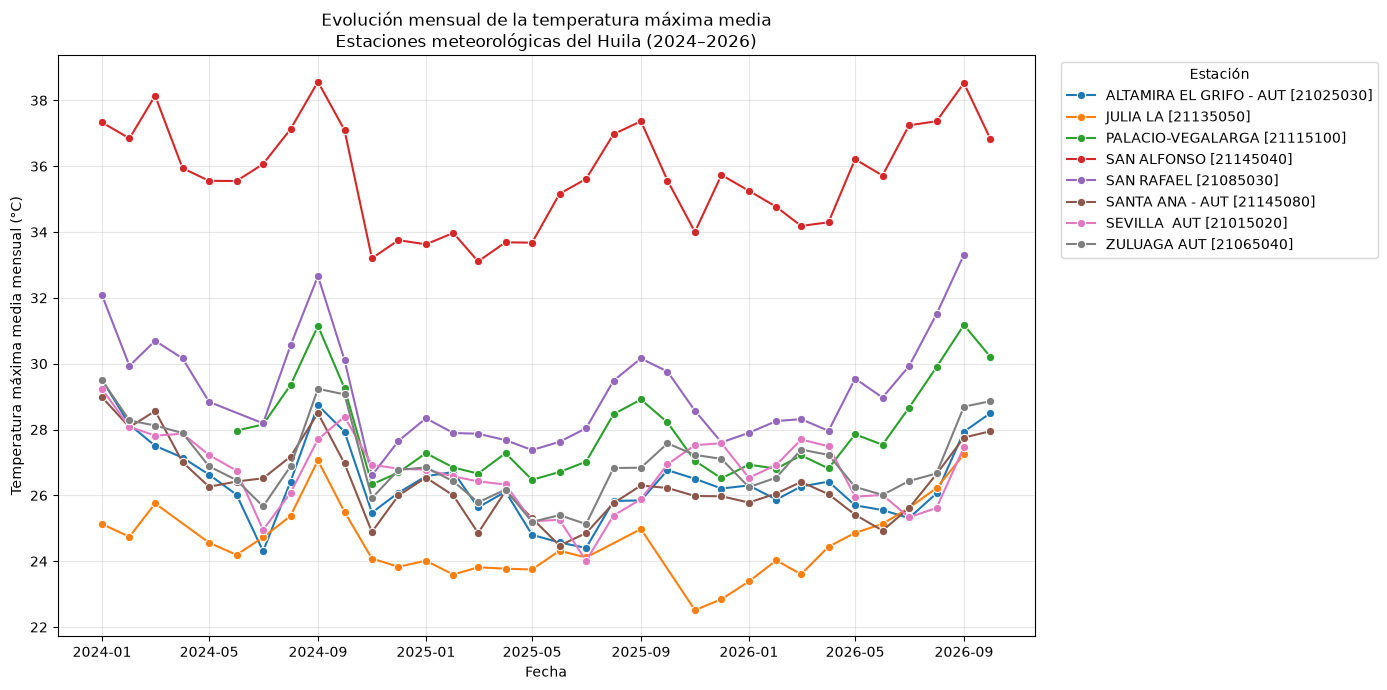

In [35]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_temp_analisis,
    x="Fecha",
    y="Temperatura_Maxima_Media",
    hue="NombreEstacion",
    marker="o"
)

plt.title(
    "Evolución mensual de la temperatura máxima media\n"
    "Estaciones meteorológicas del Huila (2024–2026)"
)

plt.xlabel("Fecha")
plt.ylabel("Temperatura máxima media mensual (°C)")
plt.legend(
    title="Estación",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
# Seleccionar las columnas necesarias
precip = df_precip_analisis[
    ["CodigoEstacion", "Fecha", "Precipitacion_Mensual"]
].copy()

temp = df_temp_analisis[
    ["CodigoEstacion", "Fecha", "Temperatura_Maxima_Media"]
].copy()

# Unir por estación y fecha
df_correlacion = pd.merge(
    precip,
    temp,
    on=["CodigoEstacion", "Fecha"],
    how="inner"
)

# Eliminar filas con valores numéricos ausentes
df_correlacion = df_correlacion.dropna(
    subset=["Precipitacion_Mensual", "Temperatura_Maxima_Media"]
)

print("Registros disponibles:", len(df_correlacion))
display(df_correlacion.head())

Registros disponibles: 258


,CodigoEstacion,Fecha,Precipitacion_Mensual,Temperatura_Maxima_Media
0,21025030,2024-01-01,9.2,29.508333
1,21025030,2024-02-01,122.8,28.150575
2,21025030,2024-03-01,143.0,27.505747
3,21025030,2024-04-01,171.0,27.146111
4,21025030,2024-05-01,227.0,26.630108


In [37]:
correlacion = df_correlacion[
    ["Precipitacion_Mensual", "Temperatura_Maxima_Media"]
].corr(method="pearson")

display(correlacion.round(3))

,Precipitacion_Mensual,Temperatura_Maxima_Media
Precipitacion_Mensual,1.000,-0.277
Temperatura_Maxima_Media,-0.277,1.000


In [38]:
correlacion_estaciones = (
    df_correlacion
    .groupby("CodigoEstacion")
    .apply(
        lambda x: x["Precipitacion_Mensual"].corr(
            x["Temperatura_Maxima_Media"]
        ),
        include_groups=False
    )
    .reset_index(name="Correlacion")
)

display(correlacion_estaciones.round(3))

,CodigoEstacion,Correlacion
0,21015020,-0.498
1,21025030,-0.263
2,21065040,-0.395
3,21085030,-0.443
4,21115100,-0.568
5,21135050,-0.524
6,21145040,-0.731
7,21145080,-0.484


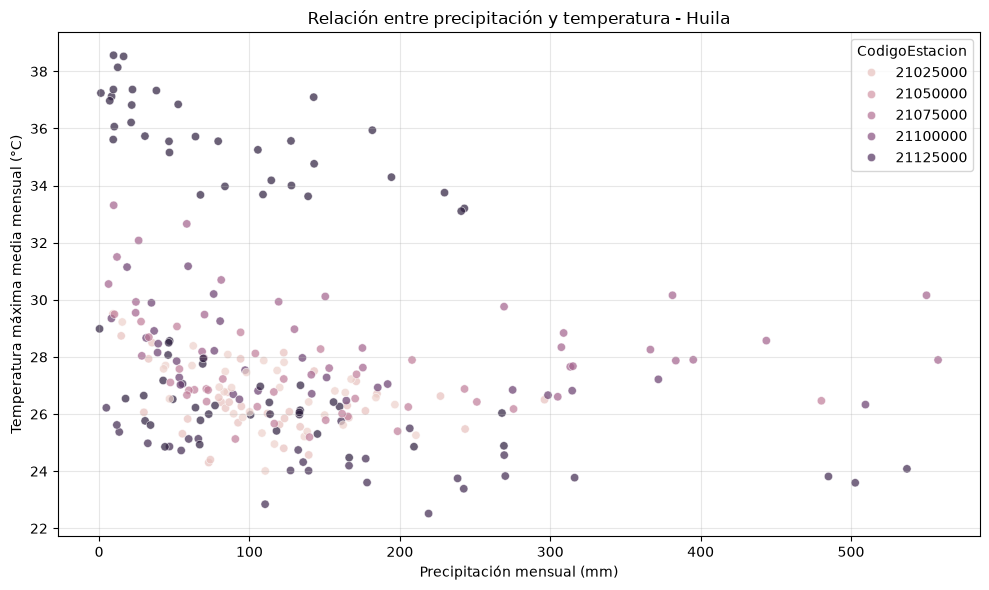

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_correlacion,
    x="Precipitacion_Mensual",
    y="Temperatura_Maxima_Media",
    hue="CodigoEstacion",
    alpha=0.7
)

plt.title("Relación entre precipitación y temperatura - Huila")
plt.xlabel("Precipitación mensual (mm)")
plt.ylabel("Temperatura máxima media mensual (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

archivo_fnc = "Precio cafe.xlsx"  

excel_fnc = pd.ExcelFile(archivo_fnc)

print("Hojas disponibles:")
for hoja in excel_fnc.sheet_names:
    print("-", hoja)

Hojas disponibles:
- Indice
- 1. Precio Interno Diario
- 2. Precio Interno Mensual
- 3. Precio Ex_Dock Mensual
- 4. Precio Ex_Dock Anual Civil
- 5.Precio Ex_Dock Anual Cafetero
- 6. Precio OIC Mensual
- 7. Área cult. dep. producto
- 8. Área cult. según tecnifi
- 8. Producción mensual
- 9. Valor cosecha


In [41]:
for hoja in excel_fnc.sheet_names:
    datos = pd.read_excel(
        archivo_fnc,
        sheet_name=hoja,
        header=None,
        nrows=8
    )

    print(f"\nHOJA: {hoja}")
    display(datos)


HOJA: Indice


,0,1,2
0,NaN,NaN,NaN
1,NaN,NaN,"Precios del café, área cultivada y producción"
2,NaN,NaN,Elaboración: Dirección de Investigaciones Econ...
3,NaN,NaN,Fecha de elaboración: Julio 2022
4,NaN,NaN,NaN
5,NaN,Pestañas,NaN
6,NaN,NaN,NaN
7,NaN,Precio interno del café colombiano,NaN



HOJA: 1. Precio Interno Diario


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,Precio Interno del Café Colombiano - Diario,NaN,NaN
2,NaN,NaN,Definición: Precio interno base de compra del ...,NaN,NaN
3,NaN,NaN,Fuente: Grabación de Precios - Almacafé,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN
5,NaN,Fecha,Precio Interno ($/125 Kg),Precio Almendra Sana ($/Kg),Incentivo a la Calidad ($/Kg)
6,NaN,2003-01-02 00:00:00,277000,NaN,NaN
7,NaN,2003-01-03 00:00:00,280875,NaN,NaN



HOJA: 2. Precio Interno Mensual


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,Precio interno base de compra del café colombi...,NaN,NaN
2,NaN,NaN,Pesos por carga de 125 kg. de café pergamino seco,NaN,NaN
3,NaN,NaN,Fuente: Grabación de Precios - Almacafé,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,Mes,Precio interno
6,NaN,NaN,NaN,1944-01-01 00:00:00,44
7,NaN,NaN,NaN,1944-02-01 00:00:00,44


... (12 outputs left out)


HOJA: 8. Producción mensual


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,Producción registrada - Mensual,NaN,NaN
2,NaN,NaN,Miles de sacos de 60 Kg de café verde equivale...,NaN,NaN
3,NaN,NaN,Fuente: Dirección de Investigaciones Económicas,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,Mes,Producción
6,NaN,NaN,NaN,1956-01-01 00:00:00,693
7,NaN,NaN,NaN,1956-02-01 00:00:00,461



HOJA: 9. Valor cosecha


,0,1,2,3,4,5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,Valor de la cosecha registrada -anual,NaN,NaN,NaN
2,NaN,NaN,Millones de pesos,NaN,NaN,NaN
3,NaN,NaN,Fuente: Gerencia Financiera - FNC,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Año Calendario,Valor de la cosecha,NaN,Año Cafetero,Valor de la cosecha
6,NaN,2000,2279049,NaN,2000/01,2009660
7,NaN,2001,1959278,NaN,2001/02,2067666


In [42]:
import pandas as pd

archivo_fnc = "Precio cafe.xlsx"

df_precios = pd.read_excel(
    archivo_fnc,
    sheet_name="2. Precio Interno Mensual",
    usecols="D:E",
    skiprows=6,
    header=None,
    names=["Fecha", "Precio_Interno_COP"]
)

df_precios["Fecha"] = pd.to_datetime(
    df_precios["Fecha"], errors="coerce"
)

df_precios["Precio_Interno_COP"] = pd.to_numeric(
    df_precios["Precio_Interno_COP"], errors="coerce"
)

df_precios = df_precios[
    df_precios["Fecha"].between("2024-01-01", "2026-10-31")
].copy()

df_precios = df_precios.sort_values("Fecha")

print("Registros:", len(df_precios))
display(df_precios.head())
display(df_precios.tail())

Registros: 34


,Fecha,Precio_Interno_COP
960,2024-01-01,1.423000e+06
961,2024-02-01,1.456862e+06
962,2024-03-01,1.440129e+06
963,2024-04-01,1.661933e+06
964,2024-05-01,1.596129e+06


,Fecha,Precio_Interno_COP
989,2026-06-01,2.086867e+06
990,2026-07-01,2.244839e+06
991,2026-08-01,2.263548e+06
992,2026-09-01,2.069100e+06
993,2026-10-01,2.120032e+06


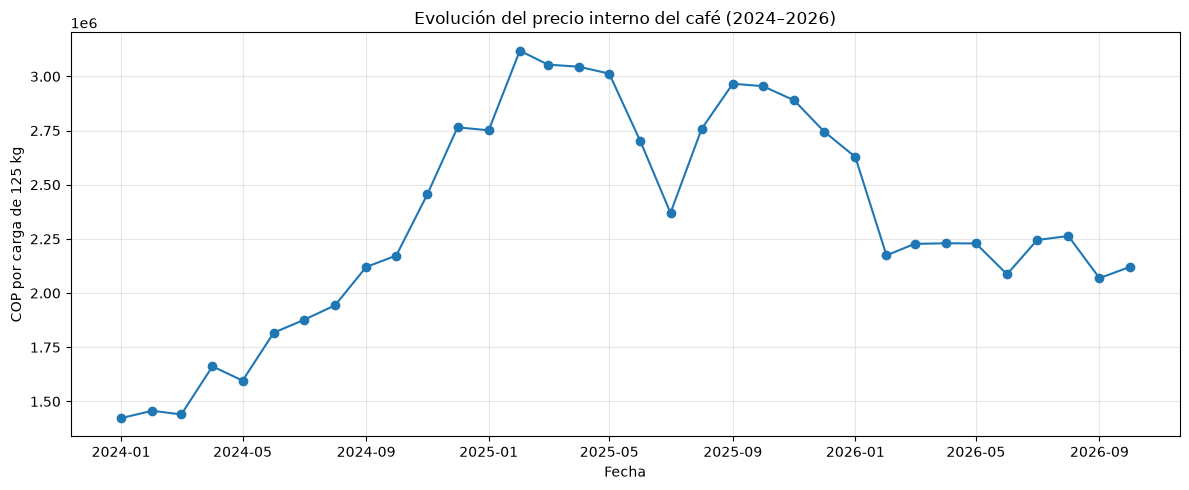

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df_precios["Fecha"],
    df_precios["Precio_Interno_COP"],
    marker="o"
)

plt.title("Evolución del precio interno del café (2024–2026)")
plt.xlabel("Fecha")
plt.ylabel("COP por carga de 125 kg")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
import pandas as pd
import numpy as np

# Trabajar sobre copias
precip = df_precip_analisis.copy()
temp = df_temp_analisis.copy()
precios = df_precios.copy()

# Estandarizar nombres de columnas
precip = precip.rename(columns={
    "Valor": "Precipitacion_Mensual"
})

temp = temp.rename(columns={
    "Valor": "Temperatura_Maxima_Media",
    "Temperatura": "Temperatura_Maxima_Media"
})

# Convertir fechas
for datos in [precip, temp, precios]:
    datos["Fecha"] = pd.to_datetime(
        datos["Fecha"], errors="coerce"
    )
    datos["Mes"] = datos["Fecha"].dt.to_period("M")

# Convertir valores numéricos
precip["Precipitacion_Mensual"] = pd.to_numeric(
    precip["Precipitacion_Mensual"], errors="coerce"
)

temp["Temperatura_Maxima_Media"] = pd.to_numeric(
    temp["Temperatura_Maxima_Media"], errors="coerce"
)

precios["Precio_Interno_COP"] = pd.to_numeric(
    precios["Precio_Interno_COP"], errors="coerce"
)

print("Bases preparadas correctamente")

Bases preparadas correctamente


In [45]:
clima = pd.merge(
    precip[
        ["CodigoEstacion", "NombreEstacion",
         "Mes", "Precipitacion_Mensual"]
    ],
    temp[
        ["CodigoEstacion", "Mes",
         "Temperatura_Maxima_Media"]
    ],
    on=["CodigoEstacion", "Mes"],
    how="outer",
    validate="one_to_one"
)

# Completar nombres de estaciones si faltan
nombres = pd.concat([
    precip[["CodigoEstacion", "NombreEstacion"]],
    temp[["CodigoEstacion", "NombreEstacion"]]
]).drop_duplicates(subset="CodigoEstacion")

clima = clima.drop(columns="NombreEstacion").merge(
    nombres,
    on="CodigoEstacion",
    how="left",
    validate="many_to_one"
)

print("Registros climáticos:", len(clima))
display(clima.head())

Registros climáticos: 266


,CodigoEstacion,Mes,Precipitacion_Mensual,Temperatura_Maxima_Media,NombreEstacion
0,21015020,2024-01,15.4,29.224167,SEVILLA AUT [21015020]
1,21015020,2024-02,85.6,28.084226,SEVILLA AUT [21015020]
2,21015020,2024-03,123.0,27.813218,SEVILLA AUT [21015020]
3,21015020,2024-04,109.5,27.873851,SEVILLA AUT [21015020]
4,21015020,2024-05,167.6,27.223734,SEVILLA AUT [21015020]


In [46]:
precios_mensuales = precios[
    ["Mes", "Precio_Interno_COP"]
].dropna().drop_duplicates()

print("Meses con precios:", len(precios_mensuales))

Meses con precios: 34


In [47]:
df_final = clima.merge(
    precios_mensuales,
    on="Mes",
    how="left",
    validate="many_to_one"
)

df_final["Fecha"] = df_final["Mes"].dt.to_timestamp()

df_final = df_final[
    ["Fecha", "Mes", "CodigoEstacion",
     "NombreEstacion", "Precipitacion_Mensual",
     "Temperatura_Maxima_Media",
     "Precio_Interno_COP"]
].sort_values(["Fecha", "CodigoEstacion"])

print("Dimensiones:", df_final.shape)
display(df_final.head(10))

Dimensiones: (266, 7)


,Fecha,Mes,CodigoEstacion,NombreEstacion,Precipitacion_Mensual,Temperatura_Maxima_Media,Precio_Interno_COP
0,2024-01-01,2024-01,21015020,SEVILLA AUT [21015020],15.4,29.224167,1423000.0
33,2024-01-01,2024-01,21025030,ALTAMIRA EL GRIFO - AUT [21025030],9.2,29.508333,1423000.0
67,2024-01-01,2024-01,21065040,ZULUAGA AUT [21065040],10.2,29.494722,1423000.0
101,2024-01-01,2024-01,21085030,SAN RAFAEL [21085030],26.3,32.078226,1423000.0
134,2024-01-01,2024-01,21115100,PALACIO-VEGALARGA [21115100],42.7,NaN,1423000.0
168,2024-01-01,2024-01,21135050,JULIA LA [21135050],59.6,25.128000,1423000.0
198,2024-01-01,2024-01,21145040,SAN ALFONSO [21145040],38.1,37.328611,1423000.0
232,2024-01-01,2024-01,21145080,SANTA ANA - AUT [21145080],0.3,28.984770,1423000.0
1,2024-02-01,2024-02,21015020,SEVILLA AUT [21015020],85.6,28.084226,1456862.0
34,2024-02-01,2024-02,21025030,ALTAMIRA EL GRIFO - AUT [21025030],122.8,28.150575,1456862.0


In [48]:
clima_mensual = (
    df_final.groupby("Mes")
    .agg(
        Precipitacion_Promedio_mm=(
            "Precipitacion_Mensual", "mean"
        ),
        Temperatura_Maxima_Promedio_C=(
            "Temperatura_Maxima_Media", "mean"
        ),
        Estaciones_Precip=(
            "Precipitacion_Mensual", "count"
        ),
        Estaciones_Temp=(
            "Temperatura_Maxima_Media", "count"
        )
    )
    .reset_index()
)

df_mensual = clima_mensual.merge(
    precios_mensuales,
    on="Mes",
    how="left",
    validate="one_to_one"
)

df_mensual["Fecha"] = df_mensual["Mes"].dt.to_timestamp()

df_mensual = df_mensual.sort_values("Fecha")

print("Meses consolidados:", len(df_mensual))
display(df_mensual.head())

Meses consolidados: 34


,Mes,Precipitacion_Promedio_mm,Temperatura_Maxima_Promedio_C,Estaciones_Precip,Estaciones_Temp,Precio_Interno_COP,Fecha
0,2024-01,25.225000,30.249547,8,7,1.423000e+06,2024-01-01
1,2024-02,102.462500,29.157413,8,7,1.456862e+06,2024-02-01
2,2024-03,98.987500,29.513947,8,7,1.440129e+06,2024-03-01
3,2024-04,196.528571,29.337053,7,6,1.661933e+06,2024-04-01
4,2024-05,198.700000,27.993204,8,7,1.596129e+06,2024-05-01


In [49]:
print("Base por estación:", df_final.shape)
print("Base mensual:", df_mensual.shape)

print("\nValores faltantes por estación:")
display(df_final.isna().sum())

print("\nValores faltantes en resumen mensual:")
display(df_mensual.isna().sum())

print("\nDuplicados estación-mes:")
print(
    df_final.duplicated(
        subset=["CodigoEstacion", "Mes"]
    ).sum()
)

print("\nDuplicados en resumen mensual:")
print(df_mensual["Mes"].duplicated().sum())

Base por estación: (266, 7)
Base mensual: (34, 7)

Valores faltantes por estación:


Fecha                       0
Mes                         0
CodigoEstacion              0
NombreEstacion              0
Precipitacion_Mensual       2
Temperatura_Maxima_Media    6
Precio_Interno_COP          0
dtype: int64


Valores faltantes en resumen mensual:


Mes                              0
Precipitacion_Promedio_mm        0
Temperatura_Maxima_Promedio_C    0
Estaciones_Precip                0
Estaciones_Temp                  0
Precio_Interno_COP               0
Fecha                            0
dtype: int64


Duplicados estación-mes:
0

Duplicados en resumen mensual:
0


In [50]:
# Copias para exportación
export_final = df_final.copy()
export_mensual = df_mensual.copy()

export_final["Mes"] = export_final["Mes"].astype(str)
export_mensual["Mes"] = export_mensual["Mes"].astype(str)

export_final.to_csv(
    "base_climatica_economica_huila.csv",
    index=False,
    encoding="utf-8-sig"
)

export_mensual.to_csv(
    "resumen_mensual_huila.csv",
    index=False,
    encoding="utf-8-sig"
)

print("¡Archivos guardados correctamente!")

¡Archivos guardados correctamente!


In [51]:
variables_modelo = [
    "Precipitacion_Promedio_mm",
    "Temperatura_Maxima_Promedio_C",
    "Precio_Interno_COP"
]

matriz_corr = df_mensual[
    variables_modelo
].corr(method="pearson")

display(matriz_corr.round(3))

,Precipitacion_Promedio_mm,Temperatura_Maxima_Promedio_C,Precio_Interno_COP
Precipitacion_Promedio_mm,1.000,-0.565,0.376
Temperatura_Maxima_Promedio_C,-0.565,1.000,-0.561
Precio_Interno_COP,0.376,-0.561,1.000


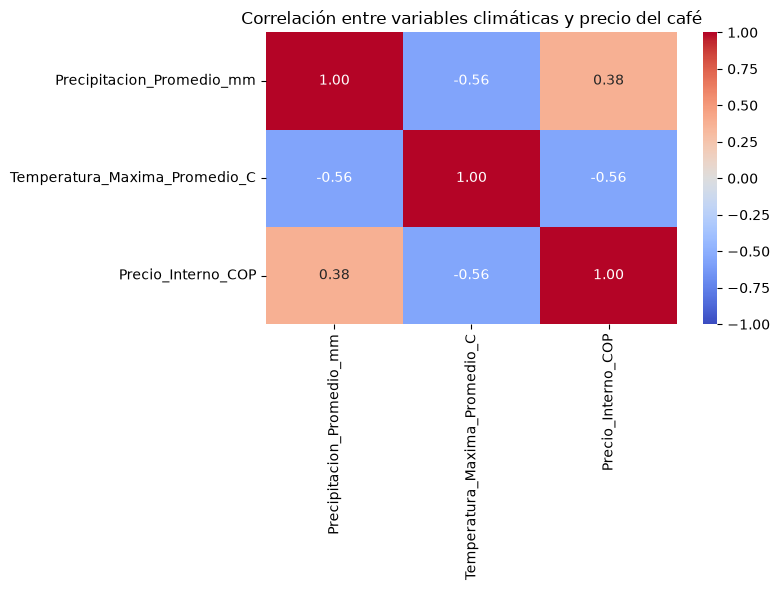

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlación entre variables climáticas y precio del café")
plt.tight_layout()
plt.show()

Coeficiente: -243998.91
Intercepto: 9186504.08
R²: 0.315


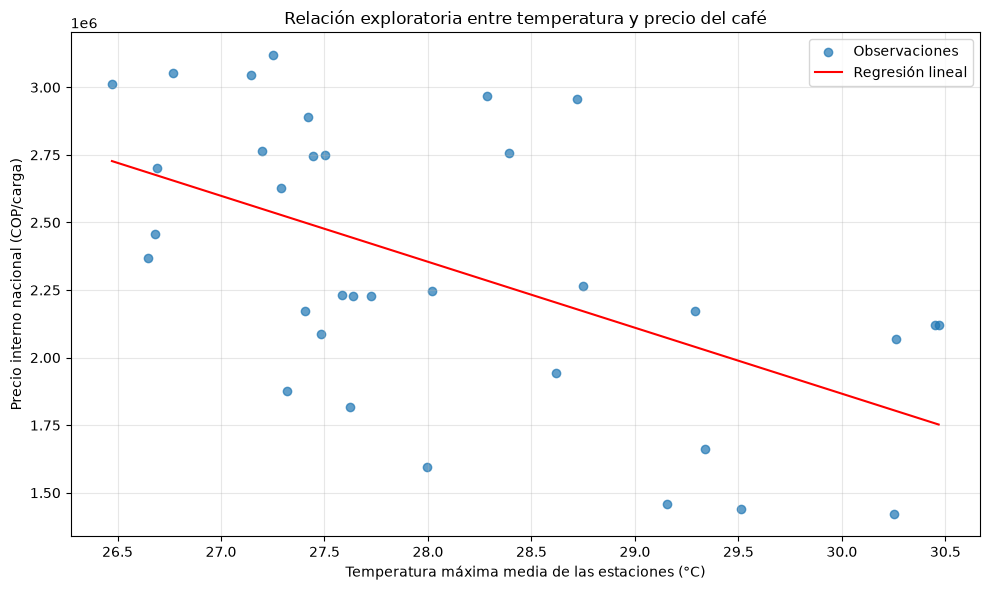

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Seleccionar las variables
datos_modelo = df_mensual[
    ["Temperatura_Maxima_Promedio_C", "Precio_Interno_COP"]
].dropna()

X = datos_modelo[["Temperatura_Maxima_Promedio_C"]]
y = datos_modelo["Precio_Interno_COP"]

# Ajustar regresión lineal
modelo = LinearRegression()
modelo.fit(X, y)

# Valores ajustados
y_ajustado = modelo.predict(X)

print("Coeficiente:", round(modelo.coef_[0], 2))
print("Intercepto:", round(modelo.intercept_, 2))
print("R²:", round(r2_score(y, y_ajustado), 3))

# Visualización
orden = np.argsort(X.iloc[:, 0].to_numpy())

plt.figure(figsize=(10, 6))

plt.scatter(
    X.iloc[:, 0],
    y,
    alpha=0.7,
    label="Observaciones"
)

plt.plot(
    X.iloc[:, 0].to_numpy()[orden],
    y_ajustado[orden],
    color="red",
    label="Regresión lineal"
)

plt.title("Relación exploratoria entre temperatura y precio del café")
plt.xlabel("Temperatura máxima media de las estaciones (°C)")
plt.ylabel("Precio interno nacional (COP/carga)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

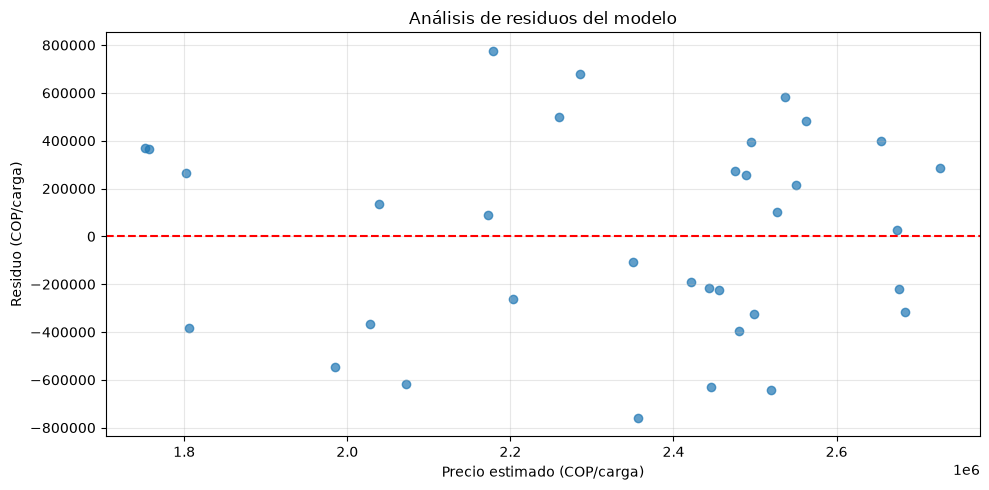

Error absoluto medio (MAE): 364437.1


In [54]:
# Calcular residuos del modelo
residuos = y - y_ajustado

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(y_ajustado, residuos, alpha=0.7)
ax.axhline(0, color="red", linestyle="--")

ax.set_title("Análisis de residuos del modelo")
ax.set_xlabel("Precio estimado (COP/carga)")
ax.set_ylabel("Residuo (COP/carga)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Error absoluto medio (MAE):",
      round(np.mean(np.abs(residuos)), 2))

In [55]:
import pandas as pd
from pathlib import Path

carpeta = Path("datos")

archivos = list(carpeta.glob("*.csv"))

bases = []

for archivo in archivos:
    nombre = archivo.stem.lower()

    departamento = next(
        (d for d in ["antioquia", "tolima", "caldas", "cauca"]
         if d in nombre),
        None
    )

    variable = (
        "Precipitacion" if "precipitacion" in nombre
        else "Temperatura" if "temperatura" in nombre
        else None
    )

    if departamento is None or variable is None:
        print("Archivo omitido:", archivo.name)
        continue

    datos = pd.read_csv(archivo, sep=None, engine="python")

    datos["Departamento"] = departamento.title()
    datos["TipoVariable"] = variable

    bases.append(datos)

if not bases:
    raise ValueError("No se encontraron archivos con nombres válidos.")

df_nuevos = pd.concat(bases, ignore_index=True)

print("Registros cargados:", len(df_nuevos))
print("Columnas:", df_nuevos.columns.tolist())

display(
    df_nuevos.groupby(
        ["Departamento", "TipoVariable"]
    ).size()
)

Registros cargados: 1929
Columnas: ['CodigoEstacion', 'NombreEstacion', 'Variable', 'Parametro', 'Fecha', 'Unidad', 'Valor', 'NivelAprobacion', 'Departamento', 'TipoVariable']


Departamento  TipoVariable 
Antioquia     Precipitacion    428
              Temperatura      298
Caldas        Precipitacion     95
              Temperatura       94
Cauca         Precipitacion    201
              Temperatura      176
Tolima        Precipitacion    316
              Temperatura      321
dtype: int64

In [56]:
resumen_estaciones = (
    df_nuevos
    .groupby(["Departamento", "TipoVariable"])
    .agg(
        Registros=("CodigoEstacion", "size"),
        Estaciones=("CodigoEstacion", "nunique"),
        Fecha_Inicial=("Fecha", "min"),
        Fecha_Final=("Fecha", "max")
    )
    .reset_index()
)

display(resumen_estaciones)

,Departamento,TipoVariable,Registros,Estaciones,Fecha_Inicial,Fecha_Final
0,Antioquia,Precipitacion,428,10,2024-01-01 00:00,2026-10-01 00:00
1,Antioquia,Temperatura,298,10,2024-01-01 00:00,2026-10-01 00:00
2,Caldas,Precipitacion,95,3,2024-01-01 00:00,2026-10-01 00:00
3,Caldas,Temperatura,94,3,2024-01-01 00:00,2026-10-01 00:00
4,Cauca,Precipitacion,201,6,2024-01-01 00:00,2026-10-01 00:00
5,Cauca,Temperatura,176,6,2024-01-01 00:00,2026-10-01 00:00
6,Tolima,Precipitacion,316,10,2024-01-01 00:00,2026-10-01 00:00
7,Tolima,Temperatura,321,10,2024-01-01 00:00,2026-10-01 00:00


In [57]:
departamentos = sorted(df_nuevos["Departamento"].unique())

resultados = []

for depto in departamentos:

    datos = df_nuevos[
        df_nuevos["Departamento"] == depto
    ]

    estaciones_precip = set(
        datos.loc[
            datos["TipoVariable"] == "Precipitacion",
            "CodigoEstacion"
        ]
    )

    estaciones_temp = set(
        datos.loc[
            datos["TipoVariable"] == "Temperatura",
            "CodigoEstacion"
        ]
    )

    resultados.append({
        "Departamento": depto,
        "Estaciones_Precip": len(estaciones_precip),
        "Estaciones_Temp": len(estaciones_temp),
        "Estaciones_Comunes": len(
            estaciones_precip & estaciones_temp
        ),
        "Solo_Precip": len(
            estaciones_precip - estaciones_temp
        ),
        "Solo_Temp": len(
            estaciones_temp - estaciones_precip
        )
    })

df_estaciones_comunes = pd.DataFrame(resultados)

display(df_estaciones_comunes)

,Departamento,Estaciones_Precip,Estaciones_Temp,Estaciones_Comunes,Solo_Precip,Solo_Temp
0,Antioquia,10,10,10,0,0
1,Caldas,3,3,3,0,0
2,Cauca,6,6,6,0,0
3,Tolima,10,10,10,0,0


In [58]:
display(
    df_nuevos.groupby(
        ["TipoVariable", "Parametro", "Unidad"]
    ).size()
)

TipoVariable   Parametro                         Unidad
Precipitacion  Precipitación total mensual       mm        1040
Temperatura    Temperatura máxima media mensual  degC       889
dtype: int64

In [59]:
# Crear una copia para auditar
df_auditoria = df_nuevos.copy()

# Normalizar fechas
df_auditoria["Fecha"] = pd.to_datetime(
    df_auditoria["Fecha"], errors="coerce"
)

df_auditoria["Mes"] = df_auditoria["Fecha"].dt.to_period("M")

# Mantener el periodo del proyecto
df_auditoria = df_auditoria[
    df_auditoria["Fecha"].between(
        "2024-01-01", "2026-10-31"
    )
].copy()

# Resumen por departamento, estación y variable
cobertura = (
    df_auditoria.groupby(
        ["Departamento", "CodigoEstacion",
         "NombreEstacion", "TipoVariable"]
    )
    .agg(
        Meses_Disponibles=("Mes", "nunique"),
        Primera_Fecha=("Fecha", "min"),
        Ultima_Fecha=("Fecha", "max")
    )
    .reset_index()
)

cobertura["Meses_Esperados"] = 34

cobertura["Meses_Faltantes"] = (
    cobertura["Meses_Esperados"]
    - cobertura["Meses_Disponibles"]
)

cobertura["Cobertura_Porcentaje"] = (
    cobertura["Meses_Disponibles"] / 34 * 100
).round(1)

display(
    cobertura.sort_values(
        ["Departamento", "TipoVariable",
         "Meses_Disponibles"]
    )
)

,Departamento,CodigoEstacion,NombreEstacion,TipoVariable,Meses_Disponibles,Primera_Fecha,Ultima_Fecha,Meses_Esperados,Meses_Faltantes,Cobertura_Porcentaje
4,Antioquia,12045010,ARBOLETES [12045010],Precipitacion,29,2024-01-01,2026-10-01,34,5,85.3
10,Antioquia,23175020,AEROPUERTO OTU [23175020],Precipitacion,31,2024-02-01,2026-09-01,34,3,91.2
14,Antioquia,26185020,MESOPOTAMIA [26185020],Precipitacion,33,2024-02-01,2026-10-01,34,1,97.1
18,Antioquia,26255020,SANTA ISABEL [26255020],Precipitacion,33,2024-01-01,2026-09-01,34,1,97.1
0,Antioquia,12015020,UNIBAN [12015020],Precipitacion,34,2024-01-01,2026-10-01,34,0,100.0
2,Antioquia,12015070,AEROPUERTO LOS CEDROS [12015070],Precipitacion,34,2024-01-01,2026-10-01,34,0,100.0
6,Antioquia,23085030,ALEJANDRÍA [23085030],Precipitacion,34,2024-01-01,2026-10-01,34,0,100.0
8,Antioquia,23085110,EL PENOL [23085110],Precipitacion,34,2024-01-01,2026-10-01,34,0,100.0
12,Antioquia,26175040,HACIENDA TUNEZ [26175040],Precipitacion,34,2024-01-01,2026-10-01,34,0,100.0
16,Antioquia,26205080,LA ALDEA [26205080],Precipitacion,34,2024-01-01,2026-10-01,34,0,100.0


In [60]:
duplicados = df_auditoria.duplicated(
    subset=[
        "Departamento",
        "CodigoEstacion",
        "TipoVariable",
        "Mes"
    ],
    keep=False
)

print("Registros duplicados:", duplicados.sum())

display(
    df_auditoria[duplicados].sort_values(
        ["Departamento", "CodigoEstacion", "Mes"]
    )
)

Registros duplicados: 196


,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion,Departamento,TipoVariable,Mes
88,12015020,UNIBAN [12015020],PRECIPITACION,Precipitación total mensual,2026-01-01,mm,407.9,Preliminar,Antioquia,Precipitacion,2026-01
1030,12015020,UNIBAN [12015020],PRECIPITACION,Precipitación total mensual,2026-01-01,mm,407.9,Preliminar,Antioquia,Precipitacion,2026-01
89,12015020,UNIBAN [12015020],PRECIPITACION,Precipitación total mensual,2026-02-01,mm,620.0,Preliminar,Antioquia,Precipitacion,2026-02
1031,12015020,UNIBAN [12015020],PRECIPITACION,Precipitación total mensual,2026-02-01,mm,620.0,Preliminar,Antioquia,Precipitacion,2026-02
90,12015020,UNIBAN [12015020],PRECIPITACION,Precipitación total mensual,2026-03-01,mm,20.9,Preliminar,Antioquia,Precipitacion,2026-03
...,...,...,...,...,...,...,...,...,...,...,...
1003,26255020,SANTA ISABEL [26255020],PRECIPITACION,Precipitación total mensual,2026-07-01,mm,468.5,Preliminar,Antioquia,Precipitacion,2026-07
86,26255020,SANTA ISABEL [26255020],PRECIPITACION,Precipitación total mensual,2026-08-01,mm,205.9,Preliminar,Antioquia,Precipitacion,2026-08
1004,26255020,SANTA ISABEL [26255020],PRECIPITACION,Precipitación total mensual,2026-08-01,mm,205.9,Preliminar,Antioquia,Precipitacion,2026-08
87,26255020,SANTA ISABEL [26255020],PRECIPITACION,Precipitación total mensual,2026-09-01,mm,312.1,Preliminar,Antioquia,Precipitacion,2026-09


In [61]:
# Distribución de registros por año
df_auditoria["Año"] = df_auditoria["Fecha"].dt.year

resumen_anual = (
    df_auditoria
    .groupby(["Departamento", "TipoVariable", "Año"])
    .size()
    .unstack(fill_value=0)
)

display(resumen_anual)

Año                         2024  2025  2026
Departamento TipoVariable                   
Antioquia    Precipitacion   113   119   196
             Temperatura     107   106    85
Caldas       Precipitacion    36    30    29
             Temperatura      36    28    30
Cauca        Precipitacion    72    71    58
             Temperatura      70    56    50
Tolima       Precipitacion   110   110    96
             Temperatura     111   111    99

In [62]:
import pandas as pd

# Cambia el nombre por el de tu archivo corregido
ruta = "datos/precipitacion_antioquia.csv"

df_antioquia_nuevo = pd.read_csv(
    ruta,
    sep=None,
    engine="python"
)

# Identificar departamento y variable
df_antioquia_nuevo["Departamento"] = "Antioquia"
df_antioquia_nuevo["TipoVariable"] = "Precipitacion"

print("Registros cargados:", len(df_antioquia_nuevo))
display(df_antioquia_nuevo.head())

Registros cargados: 330


,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion,Departamento,TipoVariable
0,12015070,AEROPUERTO LOS CEDROS [12015070],PRECIPITACION,Precipitación total mensual,2024-01-01 00:00,mm,18.6,Preliminar,Antioquia,Precipitacion
1,12015070,AEROPUERTO LOS CEDROS [12015070],PRECIPITACION,Precipitación total mensual,2024-02-01 00:00,mm,36.4,Preliminar,Antioquia,Precipitacion
2,12015070,AEROPUERTO LOS CEDROS [12015070],PRECIPITACION,Precipitación total mensual,2024-03-01 00:00,mm,128.0,Preliminar,Antioquia,Precipitacion
3,12015070,AEROPUERTO LOS CEDROS [12015070],PRECIPITACION,Precipitación total mensual,2024-04-01 00:00,mm,737.5,Preliminar,Antioquia,Precipitacion
4,12015070,AEROPUERTO LOS CEDROS [12015070],PRECIPITACION,Precipitación total mensual,2024-05-01 00:00,mm,611.1,Preliminar,Antioquia,Precipitacion


In [63]:
# Eliminar únicamente la precipitación anterior de Antioquia
df_nuevos = df_nuevos[
    ~(
        (df_nuevos["Departamento"] == "Antioquia") &
        (df_nuevos["TipoVariable"] == "Precipitacion")
    )
].copy()

# Agregar los registros corregidos
df_nuevos = pd.concat(
    [df_nuevos, df_antioquia_nuevo],
    ignore_index=True
)

print("Total de registros actualizados:", len(df_nuevos))

Total de registros actualizados: 1831


In [64]:
# Normalizar las fechas
df_nuevos["Fecha"] = pd.to_datetime(
    df_nuevos["Fecha"],
    errors="coerce"
)

df_nuevos["Año"] = df_nuevos["Fecha"].dt.year

# Comprobar registros por año
resumen_actualizado = (
    df_nuevos
    .groupby(["Departamento", "TipoVariable", "Año"])
    .size()
    .unstack(fill_value=0)
)

display(resumen_actualizado)

Año                         2024  2025  2026
Departamento TipoVariable                   
Antioquia    Precipitacion   113   119    98
             Temperatura     107   106    85
Caldas       Precipitacion    36    30    29
             Temperatura      36    28    30
Cauca        Precipitacion    72    71    58
             Temperatura      70    56    50
Tolima       Precipitacion   110   110    96
             Temperatura     111   111    99

In [65]:
df_nuevos["Mes"] = df_nuevos["Fecha"].dt.to_period("M")

duplicados = df_nuevos.duplicated(
    subset=[
        "Departamento",
        "CodigoEstacion",
        "TipoVariable",
        "Mes"
    ]
).sum()

print("Registros duplicados:", duplicados)

Registros duplicados: 0


In [66]:
# Copia de los nuevos datos
df_regional = df_nuevos.copy()

# Estandarizar códigos y valores
df_regional["CodigoEstacion"] = (
    df_regional["CodigoEstacion"].astype(str).str.strip()
)

df_regional["Valor"] = pd.to_numeric(
    df_regional["Valor"], errors="coerce"
)

df_regional["Fecha"] = pd.to_datetime(
    df_regional["Fecha"], errors="coerce"
)

df_regional["Mes"] = df_regional["Fecha"].dt.to_period("M")

# Filtrar el periodo de estudio
df_regional = df_regional[
    df_regional["Fecha"].between(
        "2024-01-01", "2026-10-31"
    )
].copy()

# Separar las variables
precip_regional = df_regional[
    df_regional["TipoVariable"] == "Precipitacion"
].copy()

temp_regional = df_regional[
    df_regional["TipoVariable"] == "Temperatura"
].copy()

# Renombrar los valores
precip_regional = precip_regional.rename(
    columns={"Valor": "Precipitacion_Mensual"}
)

temp_regional = temp_regional.rename(
    columns={"Valor": "Temperatura_Maxima_Media"}
)

# Integrar por departamento, estación y mes
df_clima_regional = precip_regional[
    ["Departamento", "CodigoEstacion", "Mes",
     "Precipitacion_Mensual"]
].merge(
    temp_regional[
        ["Departamento", "CodigoEstacion", "Mes",
         "Temperatura_Maxima_Media"]
    ],
    on=["Departamento", "CodigoEstacion", "Mes"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("Dimensiones:", df_clima_regional.shape)

print("\nCoincidencia de registros:")
display(df_clima_regional["_merge"].value_counts())

print("\nValores faltantes:")
display(df_clima_regional.isna().sum())

Dimensiones: (960, 6)

Coincidencia de registros:


_merge
both          871
left_only      71
right_only     18
Name: count, dtype: int64


Valores faltantes:


Departamento                 0
CodigoEstacion               0
Mes                          0
Precipitacion_Mensual       18
Temperatura_Maxima_Media    71
_merge                       0
dtype: int64

In [67]:
import pandas as pd

# Preparar datos del Huila
df_huila = df_final[
    ["CodigoEstacion", "Mes",
     "Precipitacion_Mensual",
     "Temperatura_Maxima_Media"]
].copy()

df_huila["Departamento"] = "Huila"

# Asegurar tipos de datos compatibles
df_huila["CodigoEstacion"] = (
    df_huila["CodigoEstacion"].astype(str).str.strip()
)

df_huila["Mes"] = pd.PeriodIndex(
    df_huila["Mes"], freq="M"
)

# Preparar los cuatro departamentos nuevos
df_otros = df_clima_regional.drop(
    columns="_merge"
).copy()

df_otros["CodigoEstacion"] = (
    df_otros["CodigoEstacion"].astype(str).str.strip()
)

df_otros["Mes"] = pd.PeriodIndex(
    df_otros["Mes"], freq="M"
)

# Unir los cinco departamentos
df_cinco_departamentos = pd.concat(
    [df_huila, df_otros],
    ignore_index=True
)

# Verificar
print("Dimensiones:",
      df_cinco_departamentos.shape)

print("\nRegistros por departamento:")
display(
    df_cinco_departamentos.groupby(
        "Departamento"
    ).size()
)

print("\nEstaciones por departamento:")
display(
    df_cinco_departamentos.groupby(
        "Departamento"
    )["CodigoEstacion"].nunique()
)

print("\nDuplicados:")
print(
    df_cinco_departamentos.duplicated(
        ["Departamento", "CodigoEstacion", "Mes"]
    ).sum()
)

Dimensiones: (1226, 5)

Registros por departamento:


Departamento
Antioquia    333
Caldas        97
Cauca        203
Huila        266
Tolima       327
dtype: int64


Estaciones por departamento:


Departamento
Antioquia    10
Caldas        3
Cauca         6
Huila         8
Tolima       10
Name: CodigoEstacion, dtype: int64


Duplicados:
0


In [68]:
df_departamental = (
    df_cinco_departamentos
    .groupby(["Departamento", "Mes"])
    .agg(
        Precipitacion_Promedio_mm=(
            "Precipitacion_Mensual", "mean"
        ),
        Temperatura_Maxima_Promedio_C=(
            "Temperatura_Maxima_Media", "mean"
        ),
        Estaciones_Precip=(
            "Precipitacion_Mensual", "count"
        ),
        Estaciones_Temp=(
            "Temperatura_Maxima_Media", "count"
        )
    )
    .reset_index()
)

print("Dimensiones:", df_departamental.shape)
display(df_departamental.head(10))

Dimensiones: (170, 6)


,Departamento,Mes,Precipitacion_Promedio_mm,Temperatura_Maxima_Promedio_C,Estaciones_Precip,Estaciones_Temp
0,Antioquia,2024-01,19.050000,30.161415,8,8
1,Antioquia,2024-02,78.710000,29.073521,10,9
2,Antioquia,2024-03,107.310000,29.768862,10,9
3,Antioquia,2024-04,372.011111,28.768411,9,9
4,Antioquia,2024-05,463.560000,28.663346,10,10
5,Antioquia,2024-06,424.277778,27.825777,9,9
6,Antioquia,2024-07,192.600000,28.650067,9,9
7,Antioquia,2024-08,289.622222,28.492106,9,9
8,Antioquia,2024-09,289.066667,28.165116,9,8
9,Antioquia,2024-10,290.240000,27.808049,10,9


In [69]:
df_clima_ampliado = (
    df_departamental
    .groupby("Mes")
    .agg(
        Precipitacion_5Deptos=(
            "Precipitacion_Promedio_mm", "mean"
        ),
        Temperatura_5Deptos=(
            "Temperatura_Maxima_Promedio_C", "mean"
        ),
        Departamentos_Precip=(
            "Precipitacion_Promedio_mm", "count"
        ),
        Departamentos_Temp=(
            "Temperatura_Maxima_Promedio_C", "count"
        )
    )
    .reset_index()
)

display(df_clima_ampliado.head())

print("Meses disponibles:", len(df_clima_ampliado))

,Mes,Precipitacion_5Deptos,Temperatura_5Deptos,Departamentos_Precip,Departamentos_Temp
0,2024-01,48.608333,27.768689,5,5
1,2024-02,134.201167,26.943269,5,5
2,2024-03,120.617833,27.385966,5,5
3,2024-04,305.092381,26.634187,5,5
4,2024-05,275.979778,26.173719,5,5


Meses disponibles: 34


In [70]:
df_modelo_ampliado = df_clima_ampliado.merge(
    df_mensual[["Mes", "Precio_Interno_COP"]],
    on="Mes",
    how="inner",
    validate="one_to_one"
)

print("Dimensiones:", df_modelo_ampliado.shape)

display(df_modelo_ampliado.head())

print("\nValores faltantes:")
display(df_modelo_ampliado.isna().sum())

Dimensiones: (34, 6)


,Mes,Precipitacion_5Deptos,Temperatura_5Deptos,Departamentos_Precip,Departamentos_Temp,Precio_Interno_COP
0,2024-01,48.608333,27.768689,5,5,1.423000e+06
1,2024-02,134.201167,26.943269,5,5,1.456862e+06
2,2024-03,120.617833,27.385966,5,5,1.440129e+06
3,2024-04,305.092381,26.634187,5,5,1.661933e+06
4,2024-05,275.979778,26.173719,5,5,1.596129e+06



Valores faltantes:


Mes                      0
Precipitacion_5Deptos    0
Temperatura_5Deptos      0
Departamentos_Precip     0
Departamentos_Temp       0
Precio_Interno_COP       0
dtype: int64

In [71]:
print("Cobertura de departamentos:")

display(
    df_modelo_ampliado[
        ["Mes", "Departamentos_Precip",
         "Departamentos_Temp"]
    ].tail(15)
)

print("\nMeses con cobertura incompleta:")

display(
    df_modelo_ampliado[
        (df_modelo_ampliado["Departamentos_Precip"] < 5) |
        (df_modelo_ampliado["Departamentos_Temp"] < 5)
    ]
)

Cobertura de departamentos:


,Mes,Departamentos_Precip,Departamentos_Temp
19,2025-08,5,5
20,2025-09,5,5
21,2025-10,5,5
22,2025-11,5,5
23,2025-12,5,5
24,2026-01,5,5
25,2026-02,5,5
26,2026-03,5,5
27,2026-04,5,5
28,2026-05,5,5



Meses con cobertura incompleta:


,Mes,Precipitacion_5Deptos,Temperatura_5Deptos,Departamentos_Precip,Departamentos_Temp,Precio_Interno_COP


,Precipitacion_5Deptos,Temperatura_5Deptos,Precio_Interno_COP
Precipitacion_5Deptos,1.000,-0.739,0.435
Temperatura_5Deptos,-0.739,1.000,-0.555
Precio_Interno_COP,0.435,-0.555,1.000


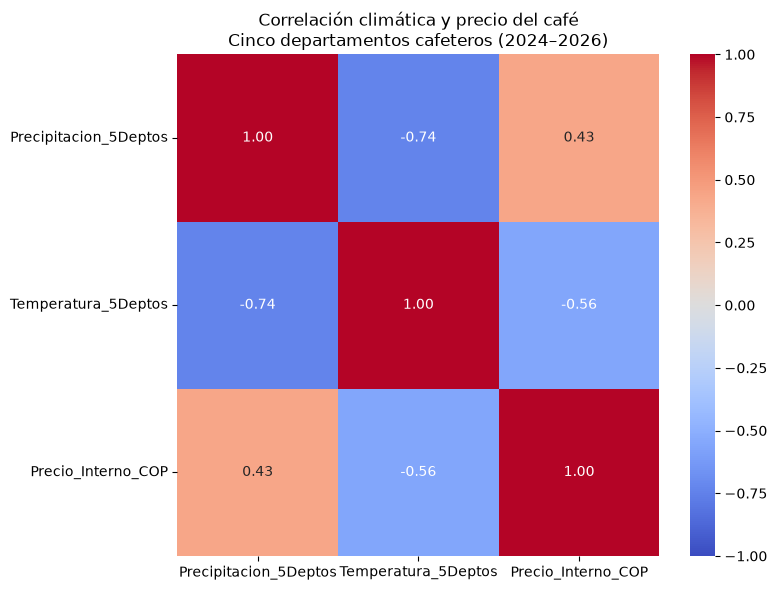

In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

variables = [
    "Precipitacion_5Deptos",
    "Temperatura_5Deptos",
    "Precio_Interno_COP"
]

correlacion_ampliada = (
    df_modelo_ampliado[variables]
    .corr(method="pearson")
)

display(correlacion_ampliada.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion_ampliada,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlación climática y precio del café\n"
    "Cinco departamentos cafeteros (2024–2026)"
)

plt.tight_layout()
plt.show()

In [73]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error
)

# Seleccionar datos
datos_ampliados = df_modelo_ampliado[
    ["Temperatura_5Deptos", "Precio_Interno_COP"]
].dropna()

X_ampliado = datos_ampliados[["Temperatura_5Deptos"]]
y_ampliado = datos_ampliados["Precio_Interno_COP"]

# Entrenar modelo
modelo_ampliado = LinearRegression()
modelo_ampliado.fit(X_ampliado, y_ampliado)

# Estimaciones dentro de la muestra
pred_ampliado = modelo_ampliado.predict(X_ampliado)

# Métricas
r2_ampliado = r2_score(y_ampliado, pred_ampliado)
mae_ampliado = mean_absolute_error(
    y_ampliado, pred_ampliado
)

print("RESULTADOS MODELO AMPLIADO")
print("--------------------------")
print("Coeficiente:", round(modelo_ampliado.coef_[0], 2))
print("Intercepto:", round(modelo_ampliado.intercept_, 2))
print("R²:", round(r2_ampliado, 3))
print("MAE:", round(mae_ampliado, 2))

RESULTADOS MODELO AMPLIADO
--------------------------
Coeficiente: -290507.28
Intercepto: 9975737.55
R²: 0.308
MAE: 357310.1


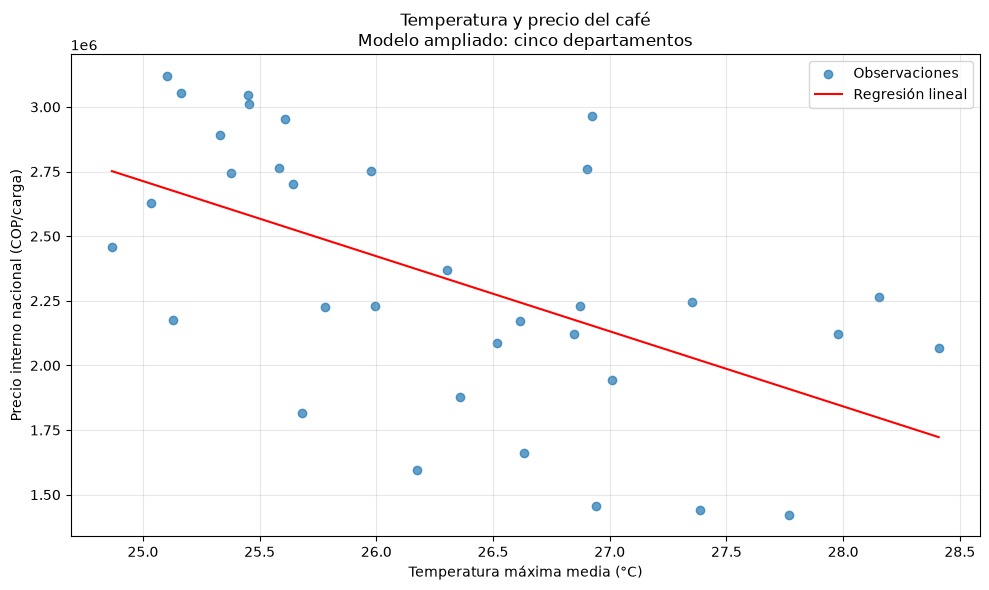

In [74]:
orden = np.argsort(
    X_ampliado.iloc[:, 0].to_numpy()
)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_ampliado.iloc[:, 0],
    y_ampliado,
    alpha=0.7,
    label="Observaciones"
)

plt.plot(
    X_ampliado.iloc[:, 0].to_numpy()[orden],
    pred_ampliado[orden],
    color="red",
    label="Regresión lineal"
)

plt.title(
    "Temperatura y precio del café\n"
    "Modelo ampliado: cinco departamentos"
)

plt.xlabel("Temperatura máxima media (°C)")
plt.ylabel("Precio interno nacional (COP/carga)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [75]:
comparacion = pd.DataFrame({
    "Modelo": [
        "Huila",
        "Cinco departamentos"
    ],
    "R²": [
        0.315,
        r2_ampliado
    ],
    "MAE_COP": [
        364437.10,
        mae_ampliado
    ]
})

display(comparacion.round(2))

,Modelo,R²,MAE_COP
0,Huila,0.32,364437.1
1,Cinco departamentos,0.31,357310.1


Correlación entre indicadores de temperatura: 0.784


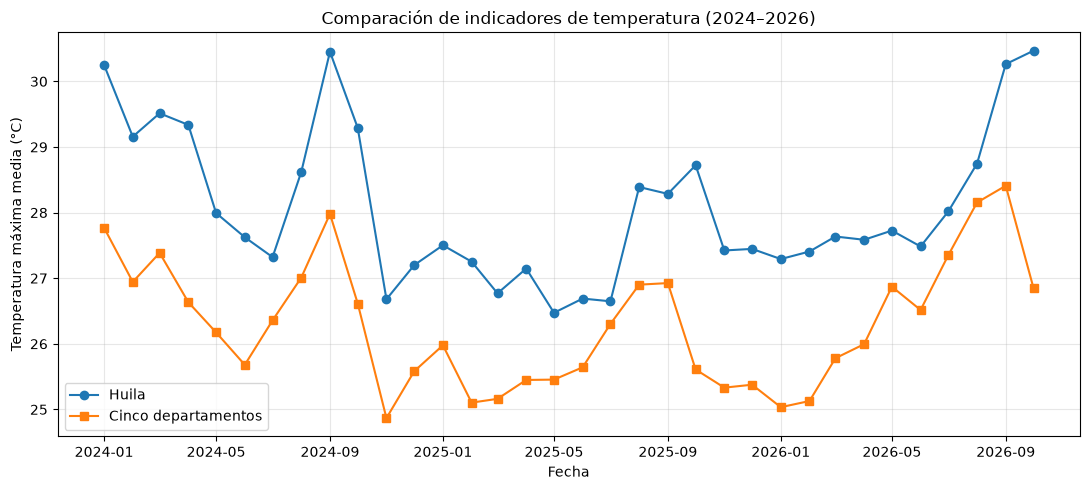

In [76]:
comparacion_clima = df_mensual[
    ["Mes", "Temperatura_Maxima_Promedio_C"]
].merge(
    df_modelo_ampliado[
        ["Mes", "Temperatura_5Deptos"]
    ],
    on="Mes",
    validate="one_to_one"
)

comparacion_clima = comparacion_clima.rename(
    columns={
        "Temperatura_Maxima_Promedio_C": "Huila",
        "Temperatura_5Deptos": "Cinco_Departamentos"
    }
)

correlacion_temperaturas = (
    comparacion_clima[["Huila", "Cinco_Departamentos"]]
    .corr()
    .iloc[0, 1]
)

print(
    "Correlación entre indicadores de temperatura:",
    round(correlacion_temperaturas, 3)
)

comparacion_clima["Fecha"] = (
    comparacion_clima["Mes"].dt.to_timestamp()
)

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(
    comparacion_clima["Fecha"],
    comparacion_clima["Huila"],
    marker="o",
    label="Huila"
)

plt.plot(
    comparacion_clima["Fecha"],
    comparacion_clima["Cinco_Departamentos"],
    marker="s",
    label="Cinco departamentos"
)

plt.title("Comparación de indicadores de temperatura (2024–2026)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura máxima media (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [78]:
import pandas as pd

bases = [
    "df_final",
    "df_nuevos",
    "df_clima_regional",
    "df_cinco_departamentos",
    "df_departamental",
    "df_modelo_ampliado"
]

for base in bases:
    if base in globals():
        print(f"✓ {base}: {globals()[base].shape}")
    else:
        print(f"✗ {base}: No disponible")

✓ df_final: (266, 7)
✓ df_nuevos: (1831, 12)
✓ df_clima_regional: (960, 6)
✓ df_cinco_departamentos: (1226, 5)
✓ df_departamental: (170, 6)
✓ df_modelo_ampliado: (34, 6)


In [79]:
import pandas as pd

df_calidad = df_cinco_departamentos.copy()

# Verificar datos faltantes por departamento
tabla_calidad = (
    df_calidad
    .groupby("Departamento")
    .agg(
        Registros=("Mes", "size"),
        Estaciones=("CodigoEstacion", "nunique"),
        Precipitacion_Disponible=(
            "Precipitacion_Mensual", "count"
        ),
        Temperatura_Disponible=(
            "Temperatura_Maxima_Media", "count"
        )
    )
    .reset_index()
)

tabla_calidad["Precipitacion_Faltante"] = (
    tabla_calidad["Registros"]
    - tabla_calidad["Precipitacion_Disponible"]
)

tabla_calidad["Temperatura_Faltante"] = (
    tabla_calidad["Registros"]
    - tabla_calidad["Temperatura_Disponible"]
)

tabla_calidad["Completitud_Precip_%"] = (
    tabla_calidad["Precipitacion_Disponible"]
    / tabla_calidad["Registros"] * 100
).round(1)

tabla_calidad["Completitud_Temp_%"] = (
    tabla_calidad["Temperatura_Disponible"]
    / tabla_calidad["Registros"] * 100
).round(1)

display(tabla_calidad)

,Departamento,Registros,Estaciones,Precipitacion_Disponible,Temperatura_Disponible,Precipitacion_Faltante,Temperatura_Faltante,Completitud_Precip_%,Completitud_Temp_%
0,Antioquia,333,10,330,298,3,35,99.1,89.5
1,Caldas,97,3,95,94,2,3,97.9,96.9
2,Cauca,203,6,201,176,2,27,99.0,86.7
3,Huila,266,8,264,260,2,6,99.2,97.7
4,Tolima,327,10,316,321,11,6,96.6,98.2


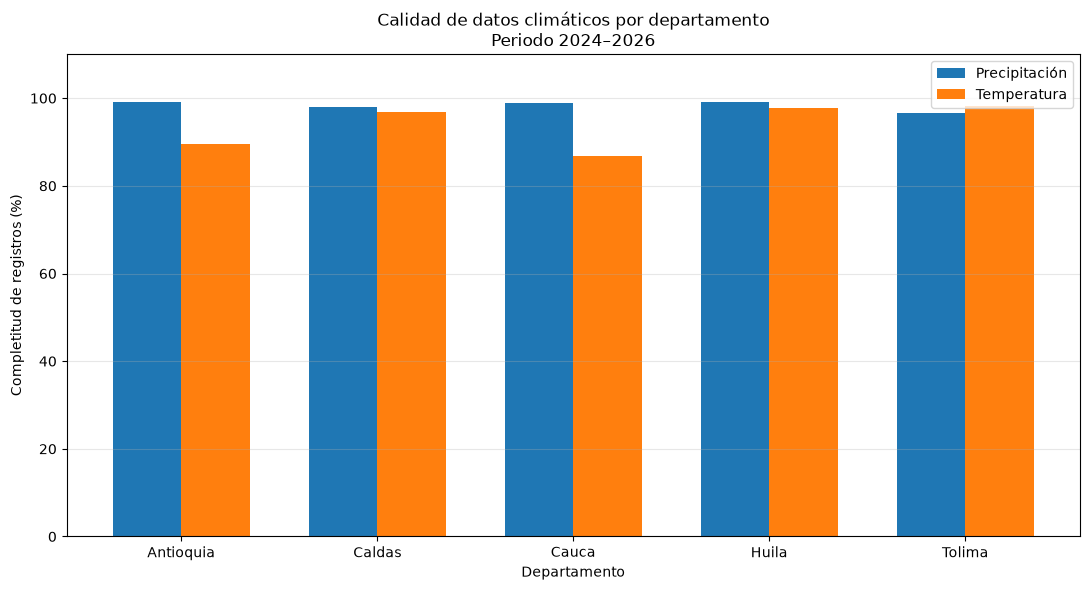

In [80]:
import matplotlib.pyplot as plt
import numpy as np

departamentos = tabla_calidad["Departamento"]
x = np.arange(len(departamentos))
ancho = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - ancho/2,
    tabla_calidad["Completitud_Precip_%"],
    width=ancho,
    label="Precipitación"
)

plt.bar(
    x + ancho/2,
    tabla_calidad["Completitud_Temp_%"],
    width=ancho,
    label="Temperatura"
)

plt.xticks(x, departamentos)
plt.ylabel("Completitud de registros (%)")
plt.xlabel("Departamento")

plt.title(
    "Calidad de datos climáticos por departamento\n"
    "Periodo 2024–2026"
)

plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "calidad_datos_departamentos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
import pandas as pd

# Seleccionar los datos del Huila
df_huila_calidad = df_cinco_departamentos[
    df_cinco_departamentos["Departamento"] == "Huila"
].copy()

# Normalizar el periodo
df_huila_calidad["Mes"] = pd.PeriodIndex(
    df_huila_calidad["Mes"], freq="M"
)

# Calcular disponibilidad por estación
tabla_calidad_huila = (
    df_huila_calidad
    .groupby(["CodigoEstacion"])
    .agg(
        Registros=("Mes", "size"),
        Meses_Disponibles=("Mes", "nunique"),
        Precipitacion_Disponible=(
            "Precipitacion_Mensual", "count"
        ),
        Temperatura_Disponible=(
            "Temperatura_Maxima_Media", "count"
        )
    )
    .reset_index()
)

# Periodo esperado: 34 meses
tabla_calidad_huila["Meses_Esperados"] = 34

tabla_calidad_huila["Precipitacion_Faltante"] = (
    34 - tabla_calidad_huila["Precipitacion_Disponible"]
)

tabla_calidad_huila["Temperatura_Faltante"] = (
    34 - tabla_calidad_huila["Temperatura_Disponible"]
)

tabla_calidad_huila["Completitud_Precip_%"] = (
    tabla_calidad_huila["Precipitacion_Disponible"]
    / 34 * 100
).round(1)

tabla_calidad_huila["Completitud_Temp_%"] = (
    tabla_calidad_huila["Temperatura_Disponible"]
    / 34 * 100
).round(1)

display(tabla_calidad_huila)

,CodigoEstacion,Registros,Meses_Disponibles,Precipitacion_Disponible,Temperatura_Disponible,Meses_Esperados,Precipitacion_Faltante,Temperatura_Faltante,Completitud_Precip_%,Completitud_Temp_%
0,21015020,33,33,33,33,34,1,1,97.1,97.1
1,21025030,34,34,34,34,34,0,0,100.0,100.0
2,21065040,34,34,34,34,34,0,0,100.0,100.0
3,21085030,33,33,33,32,34,1,2,97.1,94.1
4,21115100,34,34,34,29,34,0,5,100.0,85.3
5,21135050,30,30,28,30,34,6,4,82.4,88.2
6,21145040,34,34,34,34,34,0,0,100.0,100.0
7,21145080,34,34,34,34,34,0,0,100.0,100.0


In [82]:
print("RESUMEN DE CALIDAD - HUILA")

print(
    "Estaciones:",
    tabla_calidad_huila["CodigoEstacion"].nunique()
)

print(
    "Registros disponibles:",
    len(df_huila_calidad)
)

print(
    "Completitud precipitación:",
    round(
        tabla_calidad_huila["Precipitacion_Disponible"].sum()
        / (8 * 34) * 100, 2
    ), "%"
)

print(
    "Completitud temperatura:",
    round(
        tabla_calidad_huila["Temperatura_Disponible"].sum()
        / (8 * 34) * 100, 2
    ), "%"
)

print(
    "Duplicados estación-mes:",
    df_huila_calidad.duplicated(
        ["CodigoEstacion", "Mes"]
    ).sum()
)

RESUMEN DE CALIDAD - HUILA
Estaciones: 8
Registros disponibles: 266
Completitud precipitación: 97.06 %
Completitud temperatura: 95.59 %
Duplicados estación-mes: 0
